# EfficientNet-B0 Baseline Result Analysis

This notebook analyzes the `EfficientNet-B0` transfer learning baseline for binary diabetic retinopathy detection.
The goal is to document the quantitative test results and visualize the main evaluation figures.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "src").exists() and (candidate / "configs").exists():
        project_root = candidate
        break

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.train import build_model

config = load_yaml_config(project_root / "configs" / "efficientnet_b0_baseline.yaml")
dataset_cfg = config["dataset"]
training_cfg = config["training"]

checkpoint_path = resolve_path(project_root, config["paths"]["model_dir"]) / "best_model.pt"
figures_dir = resolve_path(project_root, config["paths"]["output_dir"])
figures_dir.mkdir(parents=True, exist_ok=True)

label_map = {0: "No DR", 1: "DR Present"}

test_records = load_fundus_records(
    csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
    images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
    image_extension=dataset_cfg.get("image_extension", ".png"),
    binary_classification=dataset_cfg.get("binary_classification", True),
)

test_dataset = FundusImageDataset(
    test_records,
    transform=default_transforms(
        image_size=dataset_cfg.get("image_size", 224),
        train=False,
        preprocessing_cfg=dataset_cfg.get("preprocessing"),
    ),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=training_cfg.get("batch_size", 16),
    shuffle=False,
    num_workers=0,
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

checkpoint = torch.load(checkpoint_path, map_location=device)
model = build_model(
    model_name=checkpoint["model_name"],
    num_classes=checkpoint["num_classes"],
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print(f"Checkpoint: {checkpoint_path}")
print(f"Device: {device}")
print(f"Test size: {len(test_dataset)}")


Checkpoint: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/models/efficientnet_b0_baseline/best_model.pt
Device: mps
Test size: 366


In [3]:
all_labels = []
all_predictions = []
all_scores = []

with torch.no_grad():
    for images, labels, _ in test_loader:
        images = images.to(device)
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_scores.extend(probabilities[:, 1].cpu().tolist())

print(f"Collected predictions for {len(all_labels)} test images.")


Collected predictions for 366 test images.


**Table 9.1. Final test-set metrics for the EfficientNet-B0 binary baseline**


In [4]:
metrics_df = pd.DataFrame(
    {
        "metric": ["accuracy", "precision", "recall", "f1_score", "roc_auc"],
        "value": [
            accuracy_score(all_labels, all_predictions),
            precision_score(all_labels, all_predictions, zero_division=0),
            recall_score(all_labels, all_predictions, zero_division=0),
            f1_score(all_labels, all_predictions, zero_division=0),
            roc_auc_score(all_labels, all_scores),
        ],
    }
)
metrics_df["value"] = metrics_df["value"].round(6)
metrics_df.to_csv(figures_dir / "table_9_1_efficientnet_b0_metrics.csv", index=False)
metrics_df


,metric,value
0,accuracy,0.989071
1,precision,0.993939
2,recall,0.982036
3,f1_score,0.987952
4,roc_auc,0.998315


**Table 9.2. Confusion-matrix counts for the EfficientNet-B0 baseline on the test split**


In [5]:
cm = confusion_matrix(all_labels, all_predictions)
tn, fp, fn, tp = cm.ravel()

cm_counts_df = pd.DataFrame(
    {
        "outcome": ["True Negative", "False Positive", "False Negative", "True Positive"],
        "count": [tn, fp, fn, tp],
    }
)
cm_counts_df.to_csv(figures_dir / "table_9_2_efficientnet_b0_confusion_counts.csv", index=False)
cm_counts_df


,outcome,count
0,True Negative,198
1,False Positive,1
2,False Negative,3
3,True Positive,164


**Figure 9.1. Confusion matrix for the EfficientNet-B0 binary baseline on the APTOS 2019 test split**


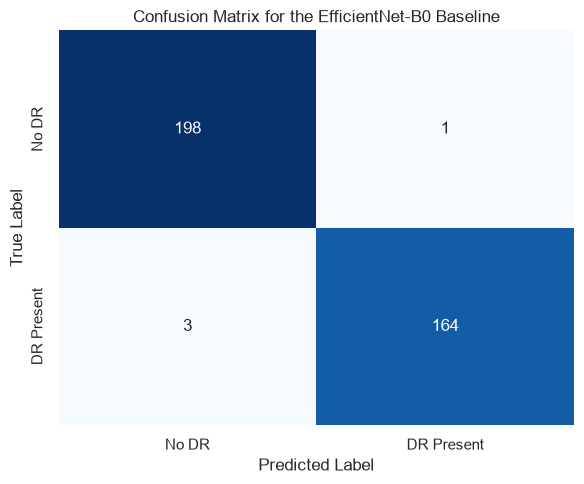

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[label_map[0], label_map[1]],
    yticklabels=[label_map[0], label_map[1]],
    ax=ax,
)
ax.set_title("Confusion Matrix for the EfficientNet-B0 Baseline")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.tight_layout()
fig.savefig(figures_dir / "figure_9_1_efficientnet_b0_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 9.2. ROC curve for the EfficientNet-B0 binary baseline on the APTOS 2019 test split**


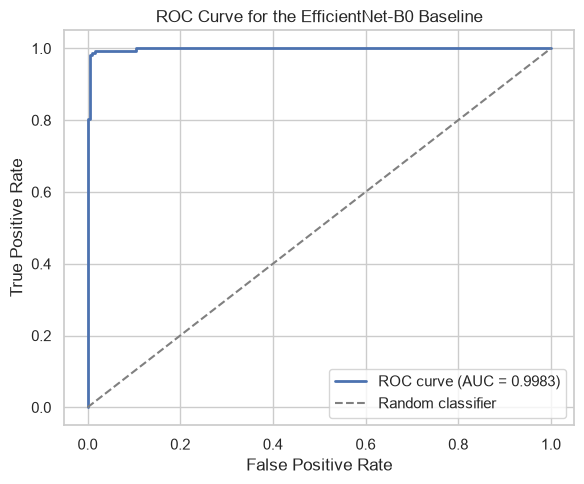

In [7]:
fpr, tpr, _ = roc_curve(all_labels, all_scores)
roc_auc = roc_auc_score(all_labels, all_scores)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, linewidth=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC Curve for the EfficientNet-B0 Baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(figures_dir / "figure_9_2_efficientnet_b0_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()
